<a href="https://colab.research.google.com/github/kubragiritkopuz/MachineLearningCourseDokuments/blob/main/BIL545_Proje1_20261007.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BIL545 · Proje 1 · Vizeye kadarki konular (2.–7. haftalar)
**Veri Madenciliğinde İleri Konular · 2026–2027 Güz** · **Vize notu** · Teslim ve sunum: **8. hafta**

Bu defter projenin şablonudur. Grubunuz defteri kendi Drive'ına kopyalar (**Dosya → Drive'a kopya kaydet**), doldurur ve **iki yere** yükler: GitHub deposundaki `proje1/` klasörüne ve STIX'teki ödev alanına. Bütün yazılı cevaplar bu defterin metin hücrelerindedir; ayrı bir rapor yoktur.

**Kapsam grup tipine göre:** 1–3 kişilik gruplar Bölüm 1–3'ü, 4 kişilik gruplar ek olarak Ek paket 1'i, 5 kişilik gruplar Ek paket 1 ve 2'yi yapar. Grubunuzun yapmadığı ek paket bölümlerini silin. Defterin sonundaki **katkı beyanı puanlanır**; sunumda her üye en az bir alt başlığı anlatır.

**Teslimden önce:** Çalışma zamanını sıfırlayıp **Çalışma Zamanı → Tümünü çalıştır** ile defteri baştan sona hatasız çalıştırın.

**Puanlama:** Başarım puanlanmaz. Her bölüm kurulumun doğruluğu (%30), kararların gerekçesi (%25), dürüst raporlama (%25), yorum (%15) ve teknik düzene (%5) göre puanlanır. Ayrıntılar: *Proje 1 ve Proje 2 Yönergesi*.

## Grup bilgisi
| | Ad Soyad | Öğrenci no |
|---|---|---|
| Üye 1 | | |
| Üye 2 *(varsa)* | | |
| Üye 3 *(varsa)* | | |
| Üye 4 *(varsa)* | | |
| Üye 5 *(varsa)* | | |

**Grup adı:**  
**GitHub deposu:**  
**Seçilen konu:** *(öneri listesindeki numarası, ör. 9.4, ya da "kendi konumuz")*  
**Grup tipi:** *(1–3 kişi / 4 kişi: + Ek paket 1 / 5 kişi: + Ek paket 1 ve 2)*  
**Veri kümesi ve sorumuz (tek cümle):**

## Hazırlık

In [36]:
import sys, warnings, numpy as np, pandas as pd, sklearn, scipy, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
SEED = 42
np.random.seed(SEED)
#pd.set_option("display.max_columns", 50, "display.width", 200)
print("Python      ", sys.version.split()[0]); print("numpy       ", np.__version__)
print("pandas      ", pd.__version__);          print("scikit-learn", sklearn.__version__)
print("scipy       ", scipy.__version__);       print("matplotlib  ", matplotlib.__version__)


Python       3.13.18
numpy        2.1.3
pandas       2.2.3
scikit-learn 1.6.1
scipy        1.16.3
matplotlib   3.10.0


### Veriyi yükleme
**Kaynak:** [Inside Airbnb · İstanbul](https://insideairbnb.com/get-the-data/) · `listings.csv.gz` (ayrıntılı ilan dosyası), yüklenme tarihi 25 Eylül 2026

**Lisans:** Creative Commons Attribution 4.0 (CC BY 4.0)

**İndirme / yükleme adımı:** Kod dosyayı Inside Airbnb sayfasından indirip açar

In [37]:
VERI_URL = "https://data.insideairbnb.com/turkey/marmara/istanbul/2026-09-25/data/listings.csv.gz"
df_ham = pd.read_csv(VERI_URL, low_memory=False)
print("Kaynak :", VERI_URL)
print("Boyut :", df_ham.shape)

Kaynak : https://data.insideairbnb.com/turkey/marmara/istanbul/2026-09-25/data/listings.csv.gz
Boyut : (27232, 90)


# Bölüm 1 · Veri, ön işleme ve sızıntı *(ağırlık 30)*
**Makale:** Kaufman vd. (2012). Leakage in data mining: Formulation, detection, and avoidance. *ACM TKDD*, 6(4).

**Okuma notu (3–4 cümle):** *Makale özeti yazılacak.-- Kübra*

[bağlantı metni](https://)### 1.1 Veri künyesi. - Doldurulacak -- Kübra
| Soru | Cevap |
|---|---|
| Kim, hangi amaçla topladı? | Veri, Inside Airbnb sitesinden elde edilmiştir. Bu site; Airbnb'den bağımsız olarak çalışan, kısa dönem kiralamanın konutlar ve mahalleler üzerindeki etkisini ölçmek üzere oluşturulan bir projedir. Veriler Airbnb sitesinde herkese açık olarak yer alan verilerin kazınması ile elde edilir. Airbnb'nin resmi sitesi değildir. |
| Hangi dönemi kapsıyor? | |
| Hedef gerçek olgu mu, vekil mi? | |
| Kimler eksik temsil ediliyor olabilir? | |
| Lisans | |

In [38]:
# Künyedeki cevapları destekleyen sayılar
tarih = lambda c: pd.to_datetime(df_ham[c], errors="coerce")
print("Veri kazıma kimliği (scrape_id):", df_ham["scrape_id"].unique())
print("Veri kazıma günleri (last_scraped):", sorted(df_ham["last_scraped"].unique()))
print("İlk yorum tarihi aralığı :", tarih("first_review").min().date(), "→", tarih("first_review").max().date())
print("Son yorum tarihi aralığı :", tarih("last_review").min().date(), "→", tarih("last_review").max().date())
print("Ev sahipliği süresi (yıl):", df_ham["hosts_time_as_host_years"].describe()[["min", "50%", "max"]].to_dict())

fiyat_ham = df_ham["price"].str.replace(r"[$,]", "", regex=True).astype(float)
print(f"\nFiyatı boş ilan oranı: {fiyat_ham.isna().mean():.1%}")
print("Fiyat teklifi gece sayısı (checkout − checkin), en sık 5 değer:")
gece = (tarih("price_quote_checkout_date") - tarih("price_quote_checkin_date")).dt.days
print(gece.value_counts().head(5).to_string())
print("\nEn az konaklama ≥ 100 gece olan ilan oranı:", f"{(df_ham['minimum_nights'] >= 100).mean():.1%}")
print("Medyan gecelik fiyat (TL), en az konaklamaya göre:")
print(fiyat_ham.groupby(np.where(df_ham["minimum_nights"] >= 100, "≥100 gece", "<100 gece")).median().round(0).to_string())

Veri kazıma kimliği (scrape_id): [20260925130056]
Veri kazıma günleri (last_scraped): ['2026-09-28', '2026-09-29']
İlk yorum tarihi aralığı : 2011-05-17 → 2026-09-28
Son yorum tarihi aralığı : 2012-01-07 → 2026-09-28
Ev sahipliği süresi (yıl): {'min': 0.0, '50%': 3.0, 'max': 15.0}

Fiyatı boş ilan oranı: 9.8%
Fiyat teklifi gece sayısı (checkout − checkin), en sık 5 değer:
1.0      8409
100.0    8215
2.0      4644
3.0      2192
5.0       453

En az konaklama ≥ 100 gece olan ilan oranı: 36.4%
Medyan gecelik fiyat (TL), en az konaklamaya göre:
<100 gece    4458.0
≥100 gece    2062.0


**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 1.2 Keşifsel analiz
Boyut; saklama ve ölçek tipleri; hedef dağılımı; yinelenen satırlar; künye tablosu (tip, eksik oranı, farklı değer sayısı, sıfır oranı); şüpheli öznitelik listesi.

In [39]:
df_ham.head(2)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,25436,https://www.airbnb.com/rooms/25436,20260925130056,2026-09-28,previous scrape,In the forest Sea view Two minutes to the city.,Our house is in Bebek Koru. If you want villag...,NaN,https://a0.muscache.com/pictures/b64c3ef0-2256...,105823,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,34177,https://www.airbnb.com/rooms/34177,20260925130056,2026-09-28,previous scrape,PETIT HOUSE,My petit house is located in the bosphorous an...,NaN,https://a0.muscache.com/pictures/47356451/c288...,147330,...,4.81,4.69,4.81,NaN,NaN,2,2,0,0,0.12


In [40]:
df_ham.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27232 entries, 0 to 27231
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            27232 non-null  int64  
 1   listing_url                                   27232 non-null  object 
 2   scrape_id                                     27232 non-null  int64  
 3   last_scraped                                  27232 non-null  object 
 4   source                                        10669 non-null  object 
 5   name                                          27232 non-null  object 
 6   description                                   27070 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   27232 non-null  object 
 9   host_id                                       27232 non-null 

In [41]:
df_ham.columns[df_ham.isna().all()].tolist() #Tamamı boş olan öznitelikler


['neighborhood_overview',
 'host_since',
 'host_response_time',
 'host_response_rate',
 'host_acceptance_rate',
 'host_thumbnail_url',
 'host_neighbourhood',
 'host_total_listings_count',
 'host_verifications',
 'neighbourhood',
 'neighbourhood_group_cleansed',
 'bathrooms',
 'calendar_updated',
 'instant_bookable']

In [42]:
df = df_ham.copy()
df["fiyat"] = df["price"].str.replace(r"[$,]", "", regex=True).astype(float)   # "$4,736.32" → 4736.32 (birim TL)

In [53]:
df_ham[["price","price_quote_total_price","price_quote_price_per_night","price_quote_raw"]].head()

,price,price_quote_total_price,price_quote_price_per_night,price_quote_raw
0,NaN,NaN,NaN,NaN
1,"$4,736.32",473632.37,4736.32,"{""quote"": {""taxes"": null, ""currency"": null, ""d..."
2,NaN,NaN,NaN,NaN
3,"$1,501.51",150150.53,1501.51,"{""quote"": {""taxes"": null, ""currency"": null, ""d..."
4,"$11,860.00",11860.00,11860.00,"{""quote"": {""taxes"": ""1270.63"", ""currency"": nul..."


In [46]:
df[["fiyat"]].head()

,fiyat
0,NaN
1,4736.32
2,NaN
3,1501.51
4,11860.00


In [54]:
#Verinin boyutu
print(f"Satır × sütun: {df_ham.shape[0]:,} × {df_ham.shape[1]}  ·  bellek: {df_ham.memory_usage(deep=True).sum()/1e6:.0f} MB")
print(f"Farklı ev sahibi: {df['host_id'].nunique():,}  ·  farklı ilçe: {df['neighbourhood_cleansed'].nunique()}")

Satır × sütun: 27,232 × 90  ·  bellek: 142 MB
Farklı ev sahibi: 9,967  ·  farklı ilçe: 39


In [74]:
print("\nFiyat tercilleri:", df["fiyat"].quantile([1/3, 2/3]).round(0).tolist())
print(df["fiyat"].describe(percentiles=[.01, .5, .99]).round(0).to_string())


Fiyat tercilleri: [2731.0, 5100.0]
count      24553.0
mean        6022.0
std        38240.0
min           79.0
1%           417.0
50%         3710.0
99%        38318.0
max      4989148.0



Hedef dağılımı (fiyatı olan ilanlar):
              count  proportion
fiyat_dilimi                   
ucuz           8311       0.338
orta           8061       0.328
pahalı         8181       0.333


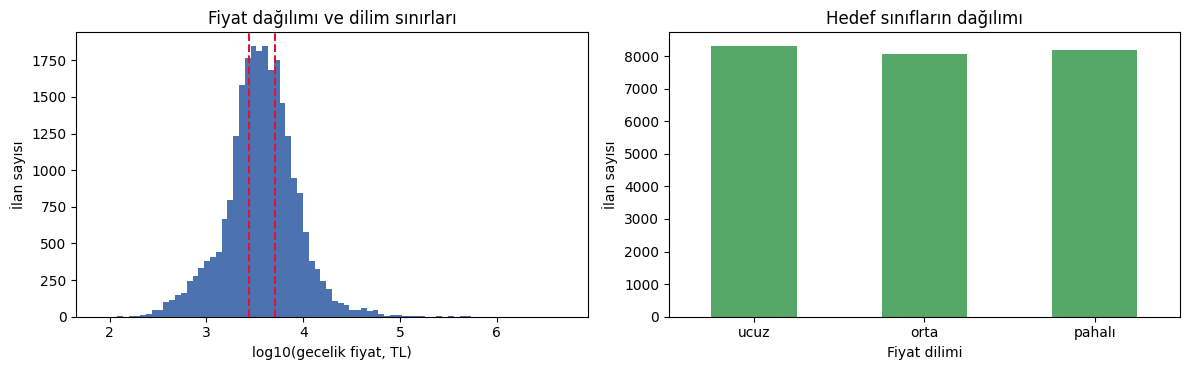

Grafik: fiyat log ölçekte sağa çarpık; kesikli çizgiler 2.750 ve 5.100 TL sınırları; sınıflar yaklaşık dengeli.


In [95]:
ESIKLER = [2750, 5100]                     # TL/gece · tercillere (≈2.731 ve ≈5.100) yakın, sabit ve okunur sınırlar
SINIFLAR = ["ucuz", "orta", "pahalı"]

df["fiyat_dilimi"] = pd.cut(df["fiyat"], [-np.inf, *ESIKLER, np.inf], labels=SINIFLAR, right=False)
print("\nHedef dağılımı (fiyatı olan ilanlar):")
print(pd.concat([df["fiyat_dilimi"].value_counts().reindex(SINIFLAR),
                 df["fiyat_dilimi"].value_counts(normalize=True).reindex(SINIFLAR).round(3)], axis=1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(np.log10(df["fiyat"].dropna()), bins=80, color="#4C72B0")
for e in ESIKLER: ax[0].axvline(np.log10(e), color="crimson", ls="--")
ax[0].set(xlabel="log10(gecelik fiyat, TL)", ylabel="İlan sayısı", title="Fiyat dağılımı ve dilim sınırları")
df["fiyat_dilimi"].value_counts().reindex(SINIFLAR).plot.bar(ax=ax[1], color="#55A868", rot=0)
ax[1].set(xlabel="Fiyat dilimi", ylabel="İlan sayısı", title="Hedef sınıfların dağılımı")
plt.tight_layout(); plt.show()
print("Grafik: fiyat log ölçekte sağa çarpık; kesikli çizgiler 2.750 ve 5.100 TL sınırları; sınıflar yaklaşık dengeli.")

Karar: Hedef = gecelik fiyatın tercillerine dayalı 3 dilim. — Gerekçe: Eşit genişlikli bölme uç değerler yüzünden kullanılamaz (ham fiyatta sınıfların biri 24.550, diğerleri 2 ve 1 ilan). Kümeleme dengesiz sınıflar verir (%16 / %56 / %28). Terciller dengeli ve uç değerlere dayanıklıdır. Alternatif olarak kişi başı fiyat ya da ilçe medyanına göre göreli fiyat, kapasite ve konum etkisini ayırmak için kullanılabilirdi; bu, Proje 2'deki ilçe tezine bağlanabilecek bir genişletme yönüdür.

In [56]:
#Yinelenen satırlar
kimlikler = ["id", "listing_url", "picture_url", "price_quote_raw"]
print("\nTam yinelenen satır (kimlik/URL sütunları hariç):", df_ham.drop(columns=kimlikler).duplicated().sum())
neredeyse = df.duplicated(["host_id", "name", "room_type", "accommodates", "neighbourhood_cleansed"], keep=False)
print("Aynı ev sahibi + aynı ad + aynı oda tipi/kapasite/ilçe olan ilan:", int(neredeyse.sum()))
ilan_sayisi = df.groupby("host_id")["id"].transform("size")
print(f"İlanların {(ilan_sayisi >= 10).mean():.1%}'i 10+ ilanı olan ev sahiplerine ait; en büyük ev sahibinin {ilan_sayisi.max()} ilanı var.")


Tam yinelenen satır (kimlik/URL sütunları hariç): 22
Aynı ev sahibi + aynı ad + aynı oda tipi/kapasite/ilçe olan ilan: 1635
İlanların 34.9%'i 10+ ilanı olan ev sahiplerine ait; en büyük ev sahibinin 347 ilanı var.


In [57]:
#Künye
kunye = pd.DataFrame({
    "saklama_tipi": df_ham.dtypes.astype(str),
    "eksik_orani": df_ham.isna().mean().round(3),
    "farkli_deger": df_ham.nunique(),
    "sifir_orani": df_ham.apply(lambda s: (s == 0).mean() if pd.api.types.is_numeric_dtype(s) else np.nan).round(3),
})
with pd.option_context("display.max_rows", 100):
    display(kunye)

,saklama_tipi,eksik_orani,farkli_deger,sifir_orani
id,int64,0.000,27232,0.000
listing_url,object,0.000,27232,NaN
scrape_id,int64,0.000,1,0.000
last_scraped,object,0.000,2,NaN
source,object,0.608,1,NaN
name,object,0.000,25571,NaN
description,object,0.006,17410,NaN
neighborhood_overview,float64,1.000,0,0.000
picture_url,object,0.000,25806,NaN
host_id,int64,0.000,9967,0.000


In [84]:
#Otomatik sızıntı taraması - fiyatla aşırı ilişkili olan satırlar
sayisal = df_ham.select_dtypes("number").columns.drop(["id", "scrape_id", "host_id", "host_profile_id"], errors="ignore")
iliski = df[sayisal].corrwith(df["fiyat"], method="spearman").abs().dropna().sort_values(ascending=False)
print("Fiyatla |Spearman| ilişkisi en yüksek 6 sayısal sütun:"); print(iliski.head(6).round(3).to_string())
print("")
print("Pearson - Spearman karşılaştırması:")
for c in ["accommodates", "bedrooms", "minimum_nights"]:
    print(f"{c:<16} Pearson: {df[c].corr(df['fiyat']):.3f} · Spearman: {df[c].corr(df['fiyat'], method='spearman'):.3f}")

Fiyatla |Spearman| ilişkisi en yüksek 6 sayısal sütun:
price_quote_price_per_night                    1.000
accommodates                                   0.518
bedrooms                                       0.390
beds                                           0.375
calculated_host_listings_count_entire_homes    0.352
minimum_nights                                 0.340

Pearson - Spearman karşılaştırması:
accommodates     Pearson: 0.093 · Spearman: 0.518
bedrooms         Pearson: 0.066 · Spearman: 0.390
minimum_nights   Pearson: -0.004 · Spearman: -0.340


#### Şüpheli öznitelik listesi ve kararlar
Liste iki aşamada oluşturuldu: (1) kurallara dayalı otomatik tarama, (2) otomatik taramaya ek olarak alan bilgisiyle eklenenler: verinin nasıl üretildiğine (Inside Airbnb sütun tanımları, 7464 sayılı Kanun) ve sütunların en sık değerlerine bakılarak bulunan sızıntı adayları ve kodlanmış değerler. "Nasıl bulundu" sütunu her satırın hangi aşamadan geldiğini gösterir.

In [92]:
# ---- (f-1) Kurallara dayalı şüpheli aday taraması
n = len(df_ham)
bulgular = []
for c in df_ham.columns:
    s = df_ham[c]
    eksik, farkli = s.isna().mean(), s.nunique()
    metin = not pd.api.types.is_numeric_dtype(s)
    if eksik == 1:
        bulgular.append((c, "1 · tamamen boş", "eksik oranı = 1")); continue
    if farkli == 1:
        bulgular.append((c, "2 · sabit", f"tek değer: {s.dropna().iloc[0]!r}, eksik %{eksik*100:.0f}"))
    if c.endswith("_url") or (farkli / n > 0.3 and c.endswith("id")) or c == "id":
        bulgular.append((c, "3 · kimlik benzeri", f"farklı değer / satır = {farkli/n:.2f}"))
    if not metin and not c.endswith("id"):
        rho = s.corr(df["fiyat"], method="spearman")
        if abs(rho) > 0.95:
            bulgular.append((c, "4 · hedefle aşırı ilişkili", f"|Spearman| = {abs(rho):.3f}"))
    if metin and s.dropna().astype(str).str.fullmatch(r"\$[\d,.]+").mean() > 0.9:
        bulgular.append((c, "5 · sayı metin olarak saklanmış", f"örnek: {s.dropna().iloc[0]!r}"))
    if metin and s.dropna().astype(str).str.len().mean() > 100 and not c.endswith("_url"):
        bulgular.append((c, "6 · uzun metin", f"ortalama {s.dropna().astype(str).str.len().mean():.0f} karakter"))

aday = pd.DataFrame(bulgular, columns=["sütun", "kural", "kanıt"]).sort_values("kural")
display(aday)

,sütun,kural,kanıt
15,host_acceptance_rate,1 · tamamen boş,eksik oranı = 1
28,calendar_updated,1 · tamamen boş,eksik oranı = 1
23,bathrooms,1 · tamamen boş,eksik oranı = 1
22,neighbourhood_group_cleansed,1 · tamamen boş,eksik oranı = 1
21,neighbourhood,1 · tamamen boş,eksik oranı = 1
20,host_verifications,1 · tamamen boş,eksik oranı = 1
19,host_total_listings_count,1 · tamamen boş,eksik oranı = 1
18,host_neighbourhood,1 · tamamen boş,eksik oranı = 1
16,host_thumbnail_url,1 · tamamen boş,eksik oranı = 1
14,host_response_rate,1 · tamamen boş,eksik oranı = 1


In [96]:
# ---- (f-2) Karar tablosu: otomatik adaylar + alan bilgisiyle eklenenler
kunye_bos = df_ham.columns[df_ham.isna().all()].tolist()
inceleme = [
    # (sütunlar, neden şüpheli, karar)
    (["id", "listing_url", "picture_url", "host_id", "host_url", "host_profile_id",
      "host_profile_url", "host_picture_url", "host_name"],
     "Kimlik benzeri / kişisel bilgi", "Modelden çıkar; host_id yalnız bölme grubu."),
    (["scrape_id", "last_scraped", "calendar_last_scraped"], "Kazıma meta verisi (1–2 değer)", "Çıkar."),
    (kunye_bos, "Tamamen boş (bu kazımada doldurulmamış)", "Çıkar."),
    (["price"], "Sayı metin olarak saklanmış ($ işareti, birim TL)", "Sayıya çevir → hedefin kaynağı (fiyat_dilimi)."),
    (["price_quote_price_per_night", "price_quote_total_price", "price_quote_raw"],
     "Hedefin kendisi / hedef × gece sayısı", "Çıkar (öznitelik sızıntısı)."),
    (["estimated_revenue_l365d"], "Hedeften türetilmiş: gelir / (fiyat × doluluk) = 1,000", "Çıkar (öznitelik sızıntısı)."),
    (["price_quote_checkin_date", "price_quote_checkout_date"], "Hedefin ölçüm koşulu", "Çıkar; künyede vekil hedef tartışması."),
    (["availability_30", "availability_60", "availability_90", "availability_365", "availability_eoy",
      "estimated_occupancy_l365d"], "Fiyatın sonucu olabilir (ters nedensellik)", "KARAR BEKLİYOR (senaryo)."),
    (["number_of_reviews_ltm", "number_of_reviews_l30d", "number_of_reviews_ly"],
     "Kazıma anına yakın dönem; fiyatın sonucu olabilir", "KARAR BEKLİYOR (senaryo)."),
    (["number_of_reviews", "reviews_per_month", "first_review", "last_review"] +
     [c for c in df_ham.columns if c.startswith("review_scores_")],
     "Yeni ilanda bilinmez; yorum yoksa yapısal eksik; puan = 0 kodlanmış eksik",
     "KARAR BEKLİYOR (senaryo). Kalırsa: reviews_per_month → 0, puan 0 → NaN."),
    (["has_availability"], "Tek değer + boş: boş = 'müsait değil'", "'f' ile doldur (1.3)."),
    (["source"], "Tek değer + boş: boş = 'city scrape'", "'guncel' / 'onceki' kategorisine çevir (1.3)."),
    (["license"], "Yer tutucu '12-3456' ve serbest metin", "Yer tutucu → NaN; durum kategorisine çevir."),
    (["bathrooms_text"], "Sayı metnin içinde ('1.5 shared baths')", "banyo_sayisi + banyo_tipi'ne ayır."),
    (["maximum_nights", "minimum_maximum_nights", "maximum_maximum_nights", "maximum_nights_avg_ntm"],
     "1125 = Airbnb varsayılanı ('sınır yok')", "Çıkar (kodlanmış değer)."),
    (["minimum_minimum_nights", "maximum_minimum_nights", "minimum_nights_avg_ntm"],
     "minimum_nights'ın takvim türevleri (aynı bilgi)", "Çıkar (tekrar eden bilgi)."),
    (["minimum_nights"], "100 gecede yığılma (7464 sayılı Kanun)", "KARAR BEKLİYOR (kapsam)."),
    (["name", "description", "host_about", "amenities"], "Metin", "Bölüm 1'de yalnız uzunluk / sayı; metin analizi Proje 2'ye."),
]

otomatik = set(aday["sütun"])                     # (f-1) taramasının bulduğu sütunlar
def nasil_bulundu(sutunlar):
    k = sum(c in otomatik for c in sutunlar)
    return "otomatik tarama" if k == len(sutunlar) else ("alan bilgisi" if k == 0 else "kısmen otomatik")

karar_tablosu = pd.DataFrame(
    [(", ".join(s), len(s), nasil_bulundu(s), neden, karar) for s, neden, karar in inceleme],
    columns=["sütun(lar)", "sayı", "nasıl bulundu", "neden şüpheli", "karar"])
with pd.option_context("display.max_colwidth", 110):
    display(karar_tablosu)

# Kapsama kontrolü: incelenen + kalan = bütün sütunlar mı?
incelenen = {c for s, _, _ in inceleme for c in s}
kalan = [c for c in df_ham.columns if c not in incelenen]
print(f"İncelenen {len(incelenen)} sütun + kalan {len(kalan)} sütun = {len(incelenen) + len(kalan)} / {df_ham.shape[1]}")
print("Otomatik taramanın bulup tabloya girmeyen sütun:", sorted(otomatik - incelenen) or "yok")
print("\nŞüpheli bulunmayan, model adayı sütunlar:"); print(kalan)

,sütun(lar),sayı,nasıl bulundu,neden şüpheli,karar
0,"id, listing_url, picture_url, host_id, host_url, host_profile_id, host_profile_url, host_picture_url, host...",9,kısmen otomatik,Kimlik benzeri / kişisel bilgi,Modelden çıkar; host_id yalnız bölme grubu.
1,"scrape_id, last_scraped, calendar_last_scraped",3,kısmen otomatik,Kazıma meta verisi (1–2 değer),Çıkar.
2,"neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thum...",14,otomatik tarama,Tamamen boş (bu kazımada doldurulmamış),Çıkar.
3,price,1,otomatik tarama,"Sayı metin olarak saklanmış ($ işareti, birim TL)",Sayıya çevir → hedefin kaynağı (fiyat_dilimi).
4,"price_quote_price_per_night, price_quote_total_price, price_quote_raw",3,kısmen otomatik,Hedefin kendisi / hedef × gece sayısı,Çıkar (öznitelik sızıntısı).
5,estimated_revenue_l365d,1,alan bilgisi,"Hedeften türetilmiş: gelir / (fiyat × doluluk) = 1,000",Çıkar (öznitelik sızıntısı).
6,"price_quote_checkin_date, price_quote_checkout_date",2,alan bilgisi,Hedefin ölçüm koşulu,Çıkar; künyede vekil hedef tartışması.
7,"availability_30, availability_60, availability_90, availability_365, availability_eoy, estimated_occupancy...",6,alan bilgisi,Fiyatın sonucu olabilir (ters nedensellik),KARAR BEKLİYOR (senaryo).
8,"number_of_reviews_ltm, number_of_reviews_l30d, number_of_reviews_ly",3,alan bilgisi,Kazıma anına yakın dönem; fiyatın sonucu olabilir,KARAR BEKLİYOR (senaryo).
9,"number_of_reviews, reviews_per_month, first_review, last_review, review_scores_rating, review_scores_accur...",11,alan bilgisi,Yeni ilanda bilinmez; yorum yoksa yapısal eksik; puan = 0 kodlanmış eksik,"KARAR BEKLİYOR (senaryo). Kalırsa: reviews_per_month → 0, puan 0 → NaN."


İncelenen 69 sütun + kalan 21 sütun = 90 / 90
Otomatik taramanın bulup tabloya girmeyen sütun: yok

Şüpheli bulunmayan, model adayı sütunlar:
['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_is_superhost', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bedrooms', 'beds', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms']


In [94]:
print("Şüpheliler dışında kalan öznitelikler:")
kalan = [c for c in df_ham.columns if c not in set(aday["sütun"])]
print(f"Hiçbir kurala takılmayan {len(kalan)} sütun:")
print(kalan)

Şüpheliler dışında kalan öznitelikler:
Hiçbir kurala takılmayan 59 sütun:
['last_scraped', 'name', 'host_name', 'hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_location', 'host_is_superhost', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'neighbourhood_cleansed', 'latitude', 'longitude', 'property_type', 'room_type', 'accommodates', 'bathrooms_text', 'bedrooms', 'beds', 'price_quote_checkin_date', 'price_quote_checkout_date', 'price_quote_total_price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'calendar_last_scraped', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'esti

In [93]:
print(len(aday))

31


**Yorum**

**Boyut ve tipler.** 27.232 ilan × 90 sütun, ama 14 sütun bu kazımada tamamen boş; fiyatı olan 24.553 ilan modele girer. Saklama tipleri yanıltıcı olabilir: `price` metin (`"$4,736.32"`, birim aslında TL), `license` serbest metin, `bathrooms_text` sayıyı metnin içinde taşıyor. Ölçek tipleri: ilçe, oda ve mülk tipi *nominal*; `fiyat_dilimi` *sıralı*; puanlar 1–5 arası ortalamalar (*aralık* gibi ele alıyoruz); kapasite, yatak, yorum sayısı ve fiyat *oran* ölçeğinde (sıfırı anlamlı).

**Hedef.** Fiyat çok çarpık: medyan 3.710 TL, ortalama 6.022 TL, en yüksek 4,99 milyon TL (148 ilan 50.000 TL'nin üstünde). Dilimleri tercillere yakın sabit sınırlarla (2.750 ve 5.100 TL) tanımladık; sınıflar dengeli (%33,8 / %32,8 / %33,3). Dilimler sıra temelli olduğu için uç değerler hedefi bozmaz: 5 milyon TL'lik ilan da yalnızca "pahalı" olur. Uç fiyatların veri hatası mı, gerçek mi olduğunu Proje 2'de (aykırı gözlem) inceleyeceğiz.

**Yinelenenler.** Tam yinelenen yalnız 22 satır var, ama asıl sorun ev sahibi düzeyinde: aynı ev sahibi, aynı ad, oda tipi, kapasite ve ilçeyle 1.635 ilan tekrarlanıyor; ilanların %34,9'u 10'dan çok ilanı olan ev sahiplerine ait, en büyüğünün 347 ilanı var. Bu ilanlar eğitim ve teste ayrı düşerse model "kopyayı" tanır: bölmeyi ev sahibine göre yapacağız (1.5'te sınanıyor).

**Fiyatla ilişkili öznitelikler.** Fiyat aşırı çarpık olduğu ve ilişkiler doğrusal değil monoton olduğu için Spearman sıra korelasyonu kullanıldı; örneğin kapasite–fiyat ilişkisi Pearson ile 0,09, Spearman ile 0,52 çıkıyor, yani Pearson uç değerler yüzünden gerçek ilişkiyi gizliyor.

**Şüpheli öznitelikler.** Otomatik tarama `price_quote_price_per_night` sütununu |ρ| = 1,000 ile hemen yakalıyor: hedefin kopyası. Ama `estimated_revenue_l365d` (tanım gereği ≈ fiyat × doluluk) yalnız ρ = 0,31 veriyor, çünkü %46'sı sıfır. Yani otomatik tarama sızıntıyı her zaman yakalamaz; kararları sütunun *nasıl üretildiğine* bakarak verdik (Kaufman vd.'nin vurgusu). Doluluk ve son dönem yorum sütunlarını da çıkardık: pahalı ilan daha az dolar, yani bunlar fiyatın nedeni değil sonucu olabilir.
Kurallara dayalı tarama 90 sütundan 31'ini aday olarak işaretledi. Ancak hiçbir kurala takılmayan 59 sütun arasında hedeften türetilmiş iki sütun (price_quote_total_price ve estimated_revenue_l365d) ve fiyatın sonucu olabilecek doluluk sütunları da var. Bu sütunlar ancak verinin nasıl üretildiği incelenerek bulunabildi. Otomatik tarama sızıntıyı bulmak için gereklidir ama yeterli değildir (Kaufman vd., 2012).

…

### 1.3 Eksiklik analizi
Eksik kodlarını `NaN`'a çevirin; deseni görselleştirin; en çok eksiği olan iki sütun için MCAR / MAR / MNAR tahmini; `add_indicator` etkisi.

In [60]:
# Kodlanmış eksiklerin NaN'a çevrilmesi
def kodlanmis_eksikleri_duzelt(d):
    d = d.copy()
    # Lisans: '12-3456' örnek numaradır (gerçek değil) → eksik
    d.loc[d["license"].isin(["12-3456", "123456", "0"]), "license"] = np.nan
    # Yorum yoksa aylık yorum sayısı 'bilinmiyor' değil, 0'dır (ters yönde kodlama: gerçek değer NaN yazılmış)
    d.loc[d["number_of_reviews"] == 0, "reviews_per_month"] = 0.0
    # source: NaN aslında 'city scrape' (güncel kazımada görülen ilan) → eksik değil, bir kategori
    d["source"] = d["source"].map({"previous scrape": "onceki"}).fillna("guncel")
    return d

once = df[["license", "reviews_per_month", "source"]].isna().mean()
df = kodlanmis_eksikleri_duzelt(df)
print("Eksik oranı (önce → sonra):")
print(pd.concat([once, df[["license", "reviews_per_month", "source"]].isna().mean()], axis=1, keys=["önce", "sonra"]).round(3).to_string())


Eksik oranı (önce → sonra):
                    önce  sonra
license            0.350  0.354
reviews_per_month  0.355  0.000
source             0.608  0.000


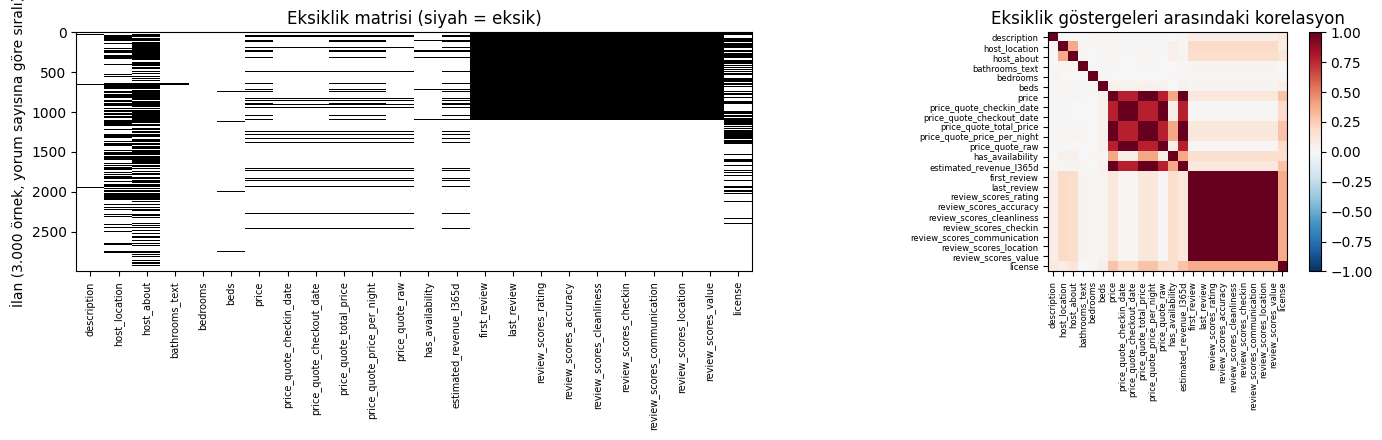

Grafik: yorum puanları ve ilk/son yorum tarihleri birlikte eksik (yorumsuz ilanlar bloğu); fiyat ve fiyat teklifi sütunları da kendi aralarında birlikte eksik.

Eksik oranı en yüksek sütunlar (tamamen boşlar hariç):
host_about                0.586
host_location             0.359
review_scores_value       0.355
review_scores_checkin     0.355
review_scores_location    0.355
review_scores_accuracy    0.355


In [61]:
# Eksiklik deseni (tamamen boş sütunlar hariç)
kismi = df_ham.columns[(df.reindex(columns=df_ham.columns).isna().mean() > 0) & (df.reindex(columns=df_ham.columns).isna().mean() < 1)]
orneklem = df.sample(3000, random_state=SEED).sort_values("number_of_reviews")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].imshow(orneklem[kismi].isna().values, aspect="auto", interpolation="nearest", cmap="Greys")
ax[0].set_xticks(range(len(kismi))); ax[0].set_xticklabels(kismi, rotation=90, fontsize=7)
ax[0].set(ylabel="İlan (3.000 örnek, yorum sayısına göre sıralı)", title="Eksiklik matrisi (siyah = eksik)")
ek = df[kismi].isna().astype(int)
im = ax[1].imshow(ek.corr().values, cmap="RdBu_r", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(kismi))); ax[1].set_xticklabels(kismi, rotation=90, fontsize=6)
ax[1].set_yticks(range(len(kismi))); ax[1].set_yticklabels(kismi, fontsize=6)
ax[1].set_title("Eksiklik göstergeleri arasındaki korelasyon"); plt.colorbar(im, ax=ax[1], fraction=0.046)
plt.tight_layout(); plt.show()
print("Grafik: yorum puanları ve ilk/son yorum tarihleri birlikte eksik (yorumsuz ilanlar bloğu); fiyat ve fiyat teklifi sütunları da kendi aralarında birlikte eksik.")

print("\nEksik oranı en yüksek sütunlar (tamamen boşlar hariç):")
print(df[kismi].isna().mean().sort_values(ascending=False).head(6).round(3).to_string())

In [62]:
# MCAR / MAR / MNAR: eksiklik göstergesi gözlenen değişkenlerle ilişkili mi?
from scipy.stats import chi2_contingency, mannwhitneyu

def eksiklik_testi(sutun):
    eksik = df[sutun].isna()
    satirlar = []
    for kat in ["host_is_superhost", "room_type", "source", "fiyat_dilimi"]:
        tablo = pd.crosstab(eksik, df[kat])
        p = chi2_contingency(tablo)[1]
        oran = df.groupby(kat, observed=True)[sutun].apply(lambda s: s.isna().mean()).round(2).to_dict()
        satirlar.append((kat, "ki-kare", p, f"eksik oranı: {oran}"))
    for say in ["calculated_host_listings_count", "hosts_time_as_host_years", "number_of_reviews"]:
        a, b = df.loc[eksik, say], df.loc[~eksik, say]
        p = mannwhitneyu(a, b).pvalue
        satirlar.append((say, "Mann-Whitney", p, f"medyan eksik={a.median():.1f} · dolu={b.median():.1f}"))
    return pd.DataFrame(satirlar, columns=["gözlenen değişken", "test", "p", "ayrıntı"])

for sutun in ["host_about", "host_location"]:
    print(f"\n=== {sutun}  (eksik oranı {df[sutun].isna().mean():.1%})")
    with pd.option_context("display.max_colwidth", 110, "display.float_format", "{:.2e}".format):
        display(eksiklik_testi(sutun))



=== host_about  (eksik oranı 58.6%)


,gözlenen değişken,test,p,ayrıntı
0,host_is_superhost,ki-kare,1.28e-91,"eksik oranı: {'f': 0.62, 't': 0.47}"
1,room_type,ki-kare,2.83e-67,"eksik oranı: {'Entire home/apt': 0.55, 'Hotel room': 0.71, 'Private room': 0.66, 'Shared room': 0.78}"
2,source,ki-kare,1.11e-66,"eksik oranı: {'guncel': 0.54, 'onceki': 0.65}"
3,fiyat_dilimi,ki-kare,3.20e-80,"eksik oranı: {'ucuz': 0.65, 'orta': 0.59, 'pahalı': 0.5}"
4,calculated_host_listings_count,Mann-Whitney,4.26e-258,medyan eksik=4.0 · dolu=8.0
5,hosts_time_as_host_years,Mann-Whitney,0.00e+00,medyan eksik=3.0 · dolu=5.0
6,number_of_reviews,Mann-Whitney,1.61e-306,medyan eksik=1.0 · dolu=8.0



=== host_location  (eksik oranı 35.9%)


,gözlenen değişken,test,p,ayrıntı
0,host_is_superhost,ki-kare,4.16e-132,"eksik oranı: {'f': 0.4, 't': 0.22}"
1,room_type,ki-kare,3.56e-95,"eksik oranı: {'Entire home/apt': 0.32, 'Hotel room': 0.62, 'Private room': 0.43, 'Shared room': 0.54}"
2,source,ki-kare,1.40e-22,"eksik oranı: {'guncel': 0.34, 'onceki': 0.39}"
3,fiyat_dilimi,ki-kare,5.65e-21,"eksik oranı: {'ucuz': 0.39, 'orta': 0.36, 'pahalı': 0.32}"
4,calculated_host_listings_count,Mann-Whitney,2.45e-116,medyan eksik=4.0 · dolu=6.0
5,hosts_time_as_host_years,Mann-Whitney,0.00e+00,medyan eksik=3.0 · dolu=4.0
6,number_of_reviews,Mann-Whitney,0.00e+00,medyan eksik=1.0 · dolu=6.0


In [63]:
# Modelde kullanılacak en eksik sütun: yorum puanları
yorumsuz = df["number_of_reviews"] == 0
print("review_scores_rating eksik ⇔ yorum sayısı 0 mı?", bool((df["review_scores_rating"].isna() == yorumsuz).all()))
print("Fiyat dilimine göre puanı eksik ilan oranı:",
      df.groupby("fiyat_dilimi", observed=True)["review_scores_rating"].apply(lambda s: s.isna().mean()).round(3).to_dict())

review_scores_rating eksik ⇔ yorum sayısı 0 mı? True
Fiyat dilimine göre puanı eksik ilan oranı: {'ucuz': 0.433, 'orta': 0.273, 'pahalı': 0.307}


#### Model tablosu ve ortak değerlendirme hattı
Bundan sonraki bütün deneyler bu tabloyu ve bu hattı kullanır. Tablodaki dönüşümler satır içidir (bir satırı dönüştürmek için başka satıra bakılmaz), bu yüzden çapraz doğrulamadan önce yapılmaları sızıntı yaratmaz. Doldurma, ölçekleme ve kodlama gibi veriden öğrenen adımlar `Pipeline` içindedir.

In [65]:
# Model tablosu: yalnız satır içi, öğrenme gerektirmeyen dönüşümler (sızıntı riski yok)
import json

def model_tablosu(d):
    t = pd.DataFrame(index=d.index)
    banyo = d["bathrooms_text"].fillna("").str.lower()
    # sayısal
    t["kapasite"] = d["accommodates"]
    t["yatak_odasi"] = d["bedrooms"]
    t["yatak"] = d["beds"]
    t["banyo_sayisi"] = np.where(banyo.str.contains("half"), 0.5, banyo.str.extract(r"([\d.]+)")[0].astype(float))
    t.loc[banyo == "", "banyo_sayisi"] = np.nan
    t["enlem"] = d["latitude"]; t["boylam"] = d["longitude"]
    t["log_min_gece"] = np.log1p(d["minimum_nights"])
    t["uzun_donem"] = (d["minimum_nights"] >= 100).astype(int)
    t["ev_sahipligi_yil"] = d["hosts_time_as_host_years"] + d["hosts_time_as_host_months"] / 12
    t["log_ev_sahibi_ilan"] = np.log1p(d["calculated_host_listings_count"])
    t["olanak_sayisi"] = d["amenities"].fillna("[]").map(lambda s: len(json.loads(s)))
    t["log_aciklama_uzunlugu"] = np.log1p(d["description"].fillna("").str.len())
    t["log_yorum_sayisi"] = np.log1p(d["number_of_reviews"])
    t["aylik_yorum"] = d["reviews_per_month"]
    for ing, tr in [("rating", "genel"), ("location", "konum"), ("cleanliness", "temizlik"), ("value", "deger")]:
        t[f"puan_{tr}"] = d[f"review_scores_{ing}"]
    # kategorik (eksikler 'bilinmiyor' / 'yok' kategorisi olur)
    t["oda_tipi"] = d["room_type"]
    t["mulk_tipi"] = d["property_type"]
    t["ilce"] = d["neighbourhood_cleansed"]
    t["superhost"] = d["host_is_superhost"]
    t["kimlik_dogrulandi"] = d["host_identity_verified"]
    t["profil_fotografi"] = d["host_has_profile_pic"]
    t["banyo_tipi"] = np.select([banyo.str.contains("shared"), banyo.str.contains("private"), banyo == ""],
                                ["paylasimli", "ozel", "bilinmiyor"], "standart")
    lis = d["license"].fillna("")
    t["lisans_durumu"] = np.select([lis == "", lis.str.contains("Non-real", case=False), lis.str.contains("Exempt", case=False)],
                                   ["yok", "gayrimenkul_degil", "muaf"], "numara")
    t["kaynak"] = d["source"]
    return t

hedefli = df[df["fiyat_dilimi"].notna()].reset_index(drop=True)
X = model_tablosu(hedefli)
y = hedefli["fiyat_dilimi"].cat.codes.to_numpy().astype(int)       # 0 = ucuz, 1 = orta, 2 = pahalı
gruplar = hedefli["host_id"].to_numpy()

SAYISAL = X.select_dtypes("number").columns.tolist()
YUKSEK_KARD = "mulk_tipi"
KATEGORIK = [c for c in X.columns if c not in SAYISAL + [YUKSEK_KARD]]
print(f"Model tablosu: {X.shape[0]:,} ilan × {X.shape[1]} öznitelik ({len(SAYISAL)} sayısal, {len(KATEGORIK)+1} kategorik)")
print(f"Fiyatı olmadığı için çıkarılan ilan: {len(df) - len(hedefli):,}")
print("Eksik içeren sütunlar:", X.isna().mean()[lambda s: s > 0].round(3).to_dict())

Model tablosu: 24,553 ilan × 27 öznitelik (18 sayısal, 9 kategorik)
Fiyatı olmadığı için çıkarılan ilan: 2,679
Eksik içeren sütunlar: {'yatak_odasi': 0.001, 'yatak': 0.014, 'banyo_sayisi': 0.004, 'puan_genel': 0.338, 'puan_konum': 0.339, 'puan_temizlik': 0.338, 'puan_deger': 0.339}


In [66]:
# ---- Ortak değerlendirme hattı (bütün bölümlerde kullanılacak)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold, RepeatedStratifiedKFold, cross_validate

NADIR_ESIK = 30   # 30'dan az ilanı olan mülk tipleri 'diğer' olarak birleşir

def on_isleme(kodlama="nadir", add_indicator=False, sayisal=None, kategorik=None, yuksek_kard=YUKSEK_KARD):
    sayisal = SAYISAL if sayisal is None else sayisal
    kategorik = KATEGORIK if kategorik is None else kategorik
    kodlayicilar = {
        "birebir": OneHotEncoder(handle_unknown="ignore"),
        "nadir":   OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=NADIR_ESIK),
        # TargetEncoder.fit_transform eğitim katı içinde kendi iç çapraz doğrulamasıyla (kat dışı) kodlar
        "hedef":   Pipeline([("te", TargetEncoder(target_type="multiclass", random_state=SEED)), ("olcek", StandardScaler())]),
    }
    parcalar = [("sayisal", Pipeline([("doldur", SimpleImputer(strategy="median", add_indicator=add_indicator)),
                                      ("olcek", StandardScaler())]), sayisal),
                ("kategorik", OneHotEncoder(handle_unknown="ignore"), kategorik)]
    if yuksek_kard is not None:
        parcalar.append(("yuksek_kard", kodlayicilar[kodlama], [yuksek_kard]))
    return ColumnTransformer(parcalar)

def lojistik():
    return LogisticRegression(max_iter=3000, random_state=SEED)

def grup_cv(y, gruplar, n_splits=5, n_repeats=5, seed=SEED):
    """Tekrarlı, katmanlı ve ev sahibine göre gruplu çapraz doğrulama: aynı ev sahibinin ilanları hep aynı katta."""
    bolmeler = []
    for r in range(n_repeats):
        sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed + r)
        bolmeler += list(sgkf.split(np.zeros(len(y)), y, gruplar))
    return bolmeler

CV_GRUP = grup_cv(y, gruplar)                                                         # doğru bölme
CV_SATIR = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED).split(X, y))  # satıra göre (karşılaştırma için)
assert all(len(set(gruplar[tr]) & set(gruplar[te])) == 0 for tr, te in CV_GRUP)
print(f"{len(CV_GRUP)} bölme · ev sahibi kesişimi yok ✓ · test katı ≈ {np.mean([len(te) for _, te in CV_GRUP]):.0f} ilan")

OLCUT = "f1_macro"
def degerlendir(model, X_, cv=CV_GRUP, ad="", olcutler=(OLCUT,)):
    s = cross_validate(model, X_, y, cv=cv, scoring=list(olcutler), n_jobs=-1)
    sonuc = {"kurulum": ad}
    for o in olcutler:
        sonuc[f"{o}_ort"], sonuc[f"{o}_std"] = s[f"test_{o}"].mean(), s[f"test_{o}"].std()
    sonuc["_skorlar"] = s[f"test_{olcutler[0]}"]
    print(f"{ad:<55s} {olcutler[0]} = {sonuc[f'{olcutler[0]}_ort']:.3f} ± {sonuc[f'{olcutler[0]}_std']:.3f}")
    return sonuc

def tablo(sonuclar):
    return pd.DataFrame(sonuclar).drop(columns="_skorlar").set_index("kurulum").round(3)

25 bölme · ev sahibi kesişimi yok ✓ · test katı ≈ 4911 ilan


#### `add_indicator` ile eksikliğin öznitelik olarak etkisi

In [67]:
# add_indicator: eksikliğin kendisini öznitelik yapmak
X_ek = X.assign(host_about_var=hedefli["host_about"].notna().astype(int),
                host_location_var=hedefli["host_location"].notna().astype(int))

sonuc_13 = [
    degerlendir(Pipeline([("on", on_isleme(add_indicator=False)), ("model", lojistik())]), X, ad="Medyan doldurma (gösterge yok)"),
    degerlendir(Pipeline([("on", on_isleme(add_indicator=True)), ("model", lojistik())]), X, ad="Medyan doldurma + add_indicator"),
    degerlendir(Pipeline([("on", on_isleme(add_indicator=True, sayisal=SAYISAL + ["host_about_var", "host_location_var"])),
                          ("model", lojistik())]), X_ek, ad="+ add_indicator + host_about/location göstergeleri"),
]
fark = sonuc_13[1]["_skorlar"] - sonuc_13[0]["_skorlar"]
print(f"\nAynı bölmelerde add_indicator farkı: {fark.mean():+.4f} ± {fark.std():.4f}  (artış olan bölme: {int((fark > 0).sum())} / {len(fark)})")
display(tablo(sonuc_13))

Medyan doldurma (gösterge yok)                          f1_macro = 0.628 ± 0.012
Medyan doldurma + add_indicator                         f1_macro = 0.629 ± 0.013
+ add_indicator + host_about/location göstergeleri      f1_macro = 0.631 ± 0.012

Aynı bölmelerde add_indicator farkı: +0.0018 ± 0.0028  (artış olan bölme: 20 / 25)


,f1_macro_ort,f1_macro_std
kurulum,,
Medyan doldurma (gösterge yok),0.628,0.012
Medyan doldurma + add_indicator,0.629,0.013
+ add_indicator + host_about/location göstergeleri,0.631,0.012


**Yorum**

**Kodlanmış eksikler.** Üç düzeltme yaptık: `license` içindeki örnek numara (`12-3456`) eksik sayıldı; yorumu olmayan ilanların `reviews_per_month` değeri NaN değil 0'dır (gerçek değer eksik gibi yazılmış); `source` sütunundaki NaN eksik değil, "güncel kazıma" anlamında bir kategoridir.

**Desen.** Eksiklik matrisi iki blok gösteriyor: yorum puanları ile ilk/son yorum tarihleri hep birlikte eksik (yorumsuz ilanlar), fiyat ile fiyat teklifi sütunları da birlikte eksik (takvimi kapalı ilanlar).

**En çok eksiği olan iki sütun (tamamen boşlar hariç):**
- `host_about` (%58,6): Eksiklik süper ev sahipliği, oda tipi, ev sahibinin ilan sayısı ve deneyimiyle güçlü ilişkili (bütün testlerde p < 10⁻⁶⁰). Süper ev sahiplerinde %47, diğerlerinde %62 eksik; deneyimli ve çok ilanlı ev sahipleri kendini daha sık tanıtıyor. Bu yüzden **MCAR değil**; gözlenen değişkenlerle açıklanabildiği için **MAR** tahmin ediyoruz. MNAR'ı dışlayamayız: tanıtım yazmayanlar "anlatacak bir şeyi olmayan" ev sahipleri olabilir; bu, eksik değerin kendisine bağlı bir neden ve veriden test edilemez.
- `host_location` (%35,9): Aynı desen (süper ev sahiplerinde %22, diğerlerinde %40 eksik; otel odalarında %62). Dolu değerlerin %90'ı zaten "İstanbul"; eksikliğin konumun kendisine bağlı olduğuna dair bir ipucu yok. Tahminimiz **MAR**.
- Modelde kullanılan en eksik sütunlar yorum puanları (%34): eksiklik **tamamen** yorum sayısının 0 olmasıyla belirleniyor (yapısal eksik). Gözlenen bir değişkenle tam açıklandığı için MAR; ucuz ilanlarda daha sık (%43, diğer dilimlerde %27–31), yani eksikliğin kendisi fiyatla ilişkili bilgi taşıyor.

**`add_indicator` etkisi.** Göstergeleri eklemek makro F1'i 0,629'dan 0,631'e çıkarıyor; aynı bölmelerde fark +0,0012 ± 0,0024 ve 25 bölmenin 16'sında artış var. Fark bölmeler arası standart sapmanın altında: anlamlı bir katkı yok. Nedeni büyük olasılıkla bilgi tekrarı: `log_yorum_sayisi = 0` zaten "puan yok" göstergesini taşıyor. `host_about` / `host_location` göstergeleri de katkı yapmadı. Zararı olmadığı ve ağaç dışı modellere yorumsuzluğu açıkça verdiği için `add_indicator=True` ile devam ediyoruz.

**Söyleyemeyeceğimiz:** MAR / MNAR ayrımı veriyle kanıtlanamaz; yaptığımız şey MCAR'ı reddetmek ve MAR'ı makul kılmaktır.

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 1.4 Kategorik kodlama
Yüksek kardinaliteli bir sütunda bire-bir, nadir kategorileri birleştiren bire-bir ve kat dışı hedef kodlama; hedef kodlamanın bir kez yanlış uygulanması.

In [68]:
# Yüksek kardinaliteli sütun: mulk_tipi (property_type)
sayim = X["mulk_tipi"].value_counts()
print(f"mulk_tipi: {sayim.size} kategori · {int((sayim < NADIR_ESIK).sum())} kategori {NADIR_ESIK}'dan az ilan içeriyor "
      f"(toplam {int(sayim[sayim < NADIR_ESIK].sum())} ilan) · {int((sayim == 1).sum())} kategoride yalnız 1 ilan")

def hat(kodlama):
    return Pipeline([("on", on_isleme(kodlama=kodlama, add_indicator=True)), ("model", lojistik())])

# Sütun sayıları (bütün veride fit yalnızca saymak için; değerlendirmede kullanılmıyor)
for k in ["birebir", "nadir", "hedef"]:
    n = on_isleme(kodlama=k).fit(X, y).named_transformers_["yuksek_kard"].transform(X[["mulk_tipi"]]).shape[1]
    print(f"  {k:<8s}: mulk_tipi {n} sütuna dönüşüyor")

sonuc_14 = [degerlendir(hat("birebir"), X, ad=f"(1) Bire-bir (one-hot), {sayim.size} kategori"),
            degerlendir(hat("nadir"),   X, ad=f"(2) Bire-bir + nadirleri birleştir (<{NADIR_ESIK})"),
            degerlendir(hat("hedef"),   X, ad="(3) Kat dışı hedef kodlama (Pipeline içinde)")]

# (4) YANLIŞ: hedef kodlama bütün veride, yumuşatmasız sınıf oranlarıyla, çapraz doğrulamadan ÖNCE
def yanlis_hedef_kodla(X_, sutun):
    oranlar = pd.crosstab(X_[sutun], y, normalize="index")          # test katlarının etiketleri de burada!
    yeni = X_[sutun].map(lambda k: tuple(oranlar.loc[k])).apply(pd.Series)
    yeni.columns = [f"te_{sutun}_{s}" for s in SINIFLAR]
    return pd.concat([X_.drop(columns=sutun), yeni], axis=1), yeni.columns.tolist()

X_yanlis, te_sutunlar = yanlis_hedef_kodla(X, "mulk_tipi")
yanlis_hat = Pipeline([("on", on_isleme(sayisal=SAYISAL + te_sutunlar, add_indicator=True, yuksek_kard=None)), ("model", lojistik())])
sonuc_14.append(degerlendir(yanlis_hat, X_yanlis, ad="(4) YANLIŞ: hedef kodlama bütün veride"))
display(tablo(sonuc_14))

mulk_tipi: 81 kategori · 58 kategori 30'dan az ilan içeriyor (toplam 430 ilan) · 17 kategoride yalnız 1 ilan
  birebir : mulk_tipi 81 sütuna dönüşüyor
  nadir   : mulk_tipi 24 sütuna dönüşüyor
  hedef   : mulk_tipi 3 sütuna dönüşüyor
(1) Bire-bir (one-hot), 81 kategori                     f1_macro = 0.629 ± 0.012
(2) Bire-bir + nadirleri birleştir (<30)                f1_macro = 0.629 ± 0.013
(3) Kat dışı hedef kodlama (Pipeline içinde)            f1_macro = 0.631 ± 0.012
(4) YANLIŞ: hedef kodlama bütün veride                  f1_macro = 0.632 ± 0.013


,f1_macro_ort,f1_macro_std
kurulum,,
"(1) Bire-bir (one-hot), 81 kategori",0.629,0.012
(2) Bire-bir + nadirleri birleştir (<30),0.629,0.013
(3) Kat dışı hedef kodlama (Pipeline içinde),0.631,0.012
(4) YANLIŞ: hedef kodlama bütün veride,0.632,0.013


#### Ek gösterim: aynı hata kimlik benzeri bir sütunda

In [69]:
# Ek gösterim: kimlik benzeri bir sütunda (host_id, 9.000+ kategori) aynı hata çok daha pahalıdır
X_host = X.assign(ev_sahibi=gruplar.astype(str))
dogru_host = Pipeline([("on", ColumnTransformer([
                          ("temel", on_isleme(kodlama="nadir", add_indicator=True), X.columns.tolist()),
                          ("ev_sahibi", Pipeline([("te", TargetEncoder(target_type="multiclass", random_state=SEED)),
                                                  ("olcek", StandardScaler())]), ["ev_sahibi"])])),
                       ("model", lojistik())])
X_host_yanlis, te_host = yanlis_hedef_kodla(X_host, "ev_sahibi")
yanlis_host = Pipeline([("on", on_isleme(sayisal=SAYISAL + te_host, add_indicator=True)), ("model", lojistik())])
sonuc_14b = [sonuc_14[1],
             degerlendir(dogru_host, X_host, ad="host_id kat dışı hedef kodlama (Pipeline içinde)"),
             degerlendir(yanlis_host, X_host_yanlis, ad="host_id YANLIŞ: hedef kodlama bütün veride")]
display(tablo(sonuc_14b))

host_id kat dışı hedef kodlama (Pipeline içinde)        f1_macro = 0.618 ± 0.011
host_id YANLIŞ: hedef kodlama bütün veride              f1_macro = 0.863 ± 0.010


,f1_macro_ort,f1_macro_std
kurulum,,
(2) Bire-bir + nadirleri birleştir (<30),0.629,0.013
host_id kat dışı hedef kodlama (Pipeline içinde),0.618,0.011
host_id YANLIŞ: hedef kodlama bütün veride,0.863,0.010


**Yorum**

**Sütun.** `mulk_tipi` (property_type) fiyatlı ilanlarda 81 kategori; 58'inde 30'dan az ilan var ama bu nadir kategoriler toplam yalnız 430 ilan (%1,8). İlanların yarısı tek kategoride ("Entire rental unit").

**Karşılaştırma.** Bire-bir 81 sütun, nadirleri birleştiren bire-bir 24 sütun, kat dışı hedef kodlama 3 sütun üretiyor; makro F1 sırasıyla 0,630 / 0,631 / 0,631 (std ≈ 0,01). Üç yöntem arasında fark yok.

**Yanlış hedef kodlama.** Bütün veride hesaplanan oranlarla skor 0,632: beklediğimizden çok daha az şişme. Nedeni, satırların %98'inin kalabalık kategorilerde olması: kalabalık bir kategoride tek bir test satırının etiketi orana neredeyse hiç etki etmez. Sızıntı yalnız nadir kategorilerde oluşur ve onlar az. Aynı hatayı kimlik benzeri `host_id` sütununda yapınca tablo değişiyor: kat dışı kodlamayla 0,618, bütün veride kodlamayla **0,864** (+25 puan). Gruplu bölmede test ev sahipleri eğitimde hiç görülmediği için doğru kodlama onlara yalnız genel ortalamayı verir (bilgi taşımaz, hatta gürültü ekler: 0,631 → 0,618); yanlış kodlama ise test ilanının kendi etiketini öznitelik olarak verir.

**Karar.** Nadirleri birleştiren bire-bir kodlamayla devam ediyoruz: başarım aynı, sütun sayısı az, katsayılar yorumlanabilir ve Weka'nın nominal öznitelikleriyle uyumlu.

**Söyleyemeyeceğimiz:** `mulk_tipi`'ndeki küçük fark "hedef kodlama sızıntısı zararsızdır" demek değildir; şişmenin büyüklüğü kategori başına düşen örnek sayısına bağlı.

…

### 1.5 Sızıntı deneyi
Ön işlemenin bütün veride yapıldığı kurulum (yanlış) ile `Pipeline` içinde yapıldığı kurulum (doğru); hata çubuklarıyla.

Lojistik regresyon · ön işleme bütün veride · satıra göre f1_macro = 0.641 ± 0.007
Lojistik regresyon · ön işleme Pipeline içinde · satıra göre f1_macro = 0.641 ± 0.006
Lojistik regresyon · ön işleme bütün veride · ev sahibine göre f1_macro = 0.632 ± 0.013
Lojistik regresyon · ön işleme Pipeline içinde · ev sahibine göre f1_macro = 0.631 ± 0.012
Rastgele orman · ön işleme bütün veride · satıra göre   f1_macro = 0.741 ± 0.004
Rastgele orman · ön işleme Pipeline içinde · satıra göre f1_macro = 0.737 ± 0.006
Rastgele orman · ön işleme bütün veride · ev sahibine göre f1_macro = 0.662 ± 0.014
Rastgele orman · ön işleme Pipeline içinde · ev sahibine göre f1_macro = 0.660 ± 0.012


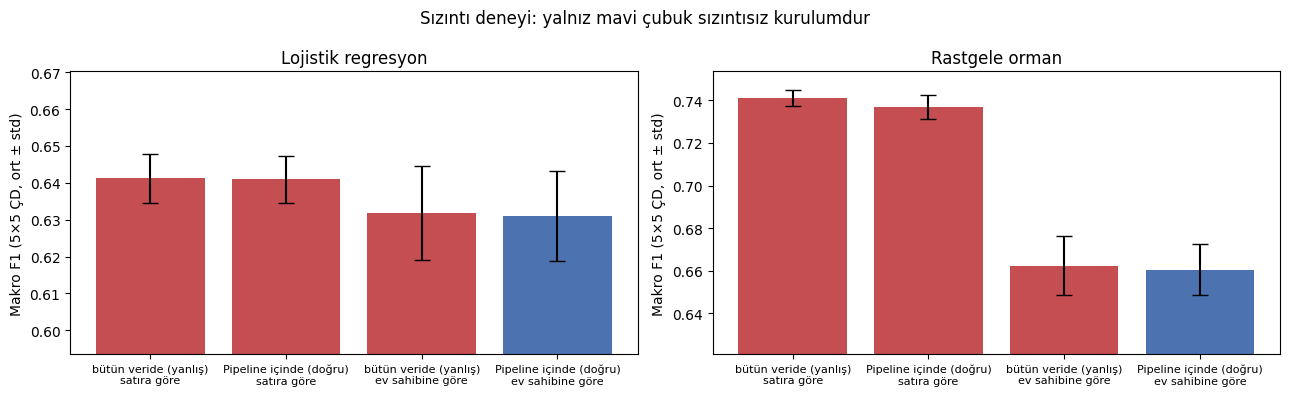

Grafik: dört kurulumun makro F1 ortalaması ve standart sapması; kırmızılar en az bir sızıntı kaynağı içeriyor. y ekseni kesik.


f1_macro_ort  \
model              on_isleme               bolme                            
Lojistik regresyon bütün veride (yanlış)   satıra göre              0.641   
                   Pipeline içinde (doğru) satıra göre              0.641   
                   bütün veride (yanlış)   ev sahibine göre         0.632   
                   Pipeline içinde (doğru) ev sahibine göre         0.631   
Rastgele orman     bütün veride (yanlış)   satıra göre              0.741   
                   Pipeline içinde (doğru) satıra göre              0.737   
                   bütün veride (yanlış)   ev sahibine göre         0.662   
                   Pipeline içinde (doğru) ev sahibine göre         0.660   

                                                             f1_macro_std  
model              on_isleme               bolme                           
Lojistik regresyon bütün veride (yanlış)   satıra göre              0.007  
                   Pipeline içinde (doğru) satıra göre              0.006  
                   bütün veride (yanlış)   ev sahibine göre         0.013  
                   Pipeline içinde (doğru) ev sahibine göre         0.012  
Rastgele orman     bütün veride (yanlış)   satıra göre              0.004  
                   Pipeline içinde (doğru) satıra göre              0.006  
                   bütün veride (yanlış)   ev sahibine göre         0.014  
                   Pipeline içinde (doğru) ev sahibine göre         0.012

In [70]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, RepeatedStratifiedKFold
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

from sklearn.ensemble import RandomForestClassifier
# Bu deneyde hatta hedefi kullanan bir adım (mulk_tipi için hedef kodlama) bilerek bırakıldı; doldurma ve ölçekleme de var.
# YANLIŞ ön işleme: bütün veride fit → sonra çapraz doğrulama.  DOĞRU: aynı adımlar Pipeline içinde, her katta yalnız eğitimde fit.
# Bölme: satıra göre (RepeatedStratifiedKFold) ve ev sahibine göre (StratifiedGroupKFold) — ikincisi bu veri için doğru olanı.
modeller = {"Lojistik regresyon": lojistik,
            "Rastgele orman": lambda: RandomForestClassifier(n_estimators=100, min_samples_leaf=2, n_jobs=-1, random_state=SEED)}

on_yanlis = on_isleme(kodlama="hedef", add_indicator=True)
Xt_yanlis = on_yanlis.fit(X, y).transform(X)        # fit(X, y).transform(X): kat içi değil, bütün veride kodlama

sonuc_15 = []
for m_ad, m in modeller.items():
    for b_ad, cv_ in [("satıra göre", CV_SATIR), ("ev sahibine göre", CV_GRUP)]:
        r = degerlendir(m(), Xt_yanlis, cv=cv_, ad=f"{m_ad} · ön işleme bütün veride · {b_ad}")
        sonuc_15.append({**r, "model": m_ad, "on_isleme": "bütün veride (yanlış)", "bolme": b_ad})
        r = degerlendir(Pipeline([("on", on_isleme(kodlama="hedef", add_indicator=True)), ("model", m())]),
                        X, cv=cv_, ad=f"{m_ad} · ön işleme Pipeline içinde · {b_ad}")
        sonuc_15.append({**r, "model": m_ad, "on_isleme": "Pipeline içinde (doğru)", "bolme": b_ad})

s15 = pd.DataFrame(sonuc_15)
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=False)
for ax, (m_ad, g) in zip(axs, s15.groupby("model", sort=False)):
    etiketler = [f"{r.on_isleme}\n{r.bolme}" for r in g.itertuples()]
    renk = ["#C44E52" if "yanlış" in r.on_isleme or r.bolme == "satıra göre" else "#4C72B0" for r in g.itertuples()]
    ax.bar(range(len(g)), g["f1_macro_ort"], yerr=g["f1_macro_std"], capsize=6, color=renk)
    ax.set_xticks(range(len(g))); ax.set_xticklabels(etiketler, fontsize=8)
    lo = (g["f1_macro_ort"] - 3 * g["f1_macro_std"]).min(); hi = (g["f1_macro_ort"] + 3 * g["f1_macro_std"]).max()
    ax.set_ylim(lo, hi); ax.set(ylabel="Makro F1 (5×5 ÇD, ort ± std)", title=m_ad)
plt.suptitle("Sızıntı deneyi: yalnız mavi çubuk sızıntısız kurulumdur"); plt.tight_layout(); plt.show()
print("Grafik: dört kurulumun makro F1 ortalaması ve standart sapması; kırmızılar en az bir sızıntı kaynağı içeriyor. y ekseni kesik.")
display(s15.drop(columns="_skorlar").set_index(["model", "on_isleme", "bolme"])[["f1_macro_ort", "f1_macro_std"]].round(3))

**Yorum**

**Ön işleme sızıntısı küçük.** Lojistik regresyonda ön işlemeyi bütün veride yapmak ile Pipeline içinde yapmak arasında fark yok (satır bölmede 0,641 / 0,641; ev sahibi bölmede 0,632 / 0,631). Rastgele ormanda fark 0,001–0,004 (0,741 / 0,737 ve 0,663 / 0,662), standart sapmanın altında. Nedeni: adımların çoğu (medyan doldurma, ölçekleme, bire-bir) hedefi kullanmıyor; hedefi kullanan tek adım kalabalık kategorili bir sütunda (1.4).

**Asıl sızıntı bölmede.** Rastgele orman satıra göre bölmede 0,737, ev sahibine göre bölmede 0,662: yaklaşık **7,5 puanlık şişme** (≈5 standart sapma). Lojistik regresyonda şişme yalnız 1 puan. Esnek model aynı ev sahibinin neredeyse aynı ilanlarını ezberleyip test katında tanıyor; doğrusal model ezberleyemiyor. Bu Kaufman vd.'nin *eğitim örneği sızıntısı*: test örneklerinin bilgisi, "kardeş" ilanlar üzerinden eğitime karışıyor. Ev sahibine göre bölmede standart sapma da daha büyük (0,014), çünkü katların ev sahibi bileşimi ve boyutları daha değişken.

**Karar.** Bundan sonraki bütün deneyler `CV_GRUP` (5×5, ev sahibine göre katmanlı gruplu bölme) ile yapılacak. Bu, "daha önce görülmemiş bir ev sahibinin ilanı" senaryosunu taklit eder.

**Söyleyemeyeceğimiz:** Senaryo farklı olsaydı (ör. platformdaki bir ev sahibinin yeni ilanı için tahmin) satıra göre bölme kısmen meşru olabilirdi. Hangi bölmenin "doğru" olduğu verinin değil, kullanım senaryosunun kararıdır.

…

### 1.6 Baseline ve ilk model
`DummyClassifier` ve tek bir basit model, sızıntısız hat içinde.

Dummy · en sık sınıf                                    f1_macro = 0.163 ± 0.007
Dummy · sınıf oranlarıyla rastgele                      f1_macro = 0.334 ± 0.006
Lojistik regresyon (sızıntısız hat)                     f1_macro = 0.629 ± 0.013


,f1_macro_ort,f1_macro_std,balanced_accuracy_ort,balanced_accuracy_std,accuracy_ort,accuracy_std
kurulum,,,,,,
Dummy · en sık sınıf,0.163,0.007,0.333,0.000,0.324,0.018
Dummy · sınıf oranlarıyla rastgele,0.334,0.006,0.335,0.006,0.335,0.006
Lojistik regresyon (sızıntısız hat),0.629,0.013,0.629,0.013,0.630,0.013


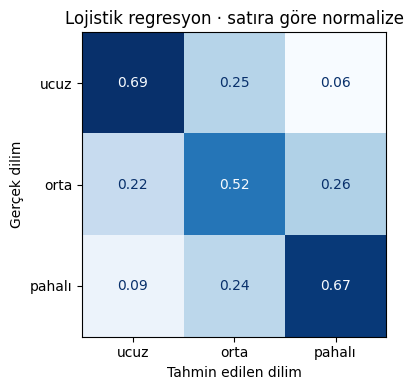

Grafik: her satır gerçek sınıfın tahminlere dağılımı; hataların çoğu komşu dilimler arasında mı?

'pahalı' ile 'ucuz' arasındaki farkı en çok belirleyen öznitelikler (katsayı farkı, ölçeklenmiş):
kategorik__ilce_Silivri                     2.03
kategorik__ilce_Adalar                      1.99
kategorik__ilce_Zeytinburnu                 1.71
sayisal__kapasite                           1.57
kategorik__ilce_Catalca                     1.38
kategorik__oda_tipi_Hotel room              1.36
kategorik__ilce_Sariyer                     1.20
yuksek_kard__mulk_tipi_Entire villa         0.90
yuksek_kard__mulk_tipi_Boat                -1.55
kategorik__ilce_Sultanbeyli                -1.55
yuksek_kard__mulk_tipi_Entire guesthouse   -1.51
kategorik__ilce_Sancaktepe                 -1.36
kategorik__ilce_Sile                       -1.32
kategorik__oda_tipi_Shared room            -1.24
kategorik__ilce_Tuzla                      -1.20
sayisal__log_min_gece                      -1.16


In [71]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

OLCUTLER = ("f1_macro", "balanced_accuracy", "accuracy")
EN_IYI_HAT = Pipeline([("on", on_isleme(kodlama="nadir", add_indicator=True)), ("model", lojistik())])   # 1.3 ve 1.4 kararları
sonuc_16 = [
    degerlendir(DummyClassifier(strategy="most_frequent"), X, ad="Dummy · en sık sınıf", olcutler=OLCUTLER),
    degerlendir(DummyClassifier(strategy="stratified", random_state=SEED), X, ad="Dummy · sınıf oranlarıyla rastgele", olcutler=OLCUTLER),
    degerlendir(EN_IYI_HAT, X, ad="Lojistik regresyon (sızıntısız hat)", olcutler=OLCUTLER),
]
display(tablo(sonuc_16))

# Karışıklık matrisi: tek bir 5 katlı gruplu bölmede kat dışı tahminler
tahmin = cross_val_predict(EN_IYI_HAT, X, y, cv=CV_GRUP[:5], n_jobs=-1)
fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(confusion_matrix(y, tahmin, normalize="true"), display_labels=SINIFLAR).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
ax.set(xlabel="Tahmin edilen dilim", ylabel="Gerçek dilim", title="Lojistik regresyon · satıra göre normalize")
plt.tight_layout(); plt.show()
print("Grafik: her satır gerçek sınıfın tahminlere dağılımı; hataların çoğu komşu dilimler arasında mı?")

# Hangi öznitelikler? (bütün veride fit, yalnız yorum için; skor raporlamada kullanılmıyor)
EN_IYI_HAT.fit(X, y)
adlar = EN_IYI_HAT.named_steps["on"].get_feature_names_out()
katsayi = pd.Series(EN_IYI_HAT.named_steps["model"].coef_[2] - EN_IYI_HAT.named_steps["model"].coef_[0], index=adlar)
print("\n'pahalı' ile 'ucuz' arasındaki farkı en çok belirleyen öznitelikler (katsayı farkı, ölçeklenmiş):")
print(pd.concat([katsayi.nlargest(8), katsayi.nsmallest(8)]).round(2).to_string())

**Yorum**

**Ölçüt.** Ana ölçüt makro F1: sınıflar dengeli olduğu için doğruluk da yanıltıcı değil (üç ölçüt neredeyse aynı çıkıyor), ama makro F1 her dilime eşit ağırlık verir ve Bölüm 2'de sınıf dengesi değişse de karşılaştırılabilir kalır.

**Sonuç.** En sık sınıfı söyleyen baseline makro F1 = 0,169 (doğruluk 0,338), sınıf oranlarıyla rastgele tahmin 0,335. Lojistik regresyon sızıntısız hatta **0,631 ± 0,010** (dengeli doğruluk 0,630 ± 0,010): baseline'ın yaklaşık iki katı, ama ilanların üçte biri hâlâ yanlış dilimde.

**Hatalar.** Karışıklık matrisinde ucuzların %69'u, pahalıların %67'si doğru; orta dilim en zor (%53), çünkü iki komşusuyla sınır paylaşıyor. Hataların yalnız %14'ü "ucuz ↔ pahalı" atlaması; geri kalanı komşu dilimler arasında. Model fiyat sırasını büyük ölçüde öğrenmiş, sınırlarda kararsız.

**Öznitelikler (nedensel değil).** "Pahalı" yönünde en güçlü katsayılar bazı ilçeler (Silivri, Adalar, Zeytinburnu, Çatalca, Sarıyer), kapasite ve otel odası; "ucuz" yönünde paylaşımlı oda, bazı çevre ilçeler ve uzun en az konaklama. Son bulgu büyük olasılıkla bir ölçüm etkisi (100 gecelik tekliflerin gece başı fiyatı düşük; 1.1). Katsayılar bire-bir kodlanmış ve birbiriyle ilişkili özniteliklerden geldiği için yalnız yön olarak okunmalı; Silivri ve Çatalca'nın "pahalı" çıkması, oradaki az sayıdaki ilanın villa ağırlıklı olmasının sonucu olabilir.

…

### 1.7 Weka ile bağımsız kontrol
ZeroR ve J48, 10 kat çapraz doğrulama; çıktıyı yapıştırın ve Python ile tutarlılığını yorumlayın.

In [ ]:
weka_cikti = """

"""

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Bölüm 2 · Sınıflandırma ve dürüst model değerlendirme *(ağırlık 30)*
**Makale:** Dietterich (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation*, 10(7).

**Okuma notu (3–4 cümle):** …

### 2.1 Model karşılaştırması
Baseline, karar ağacı, k-NN, rastgele orman, gradyan artırma; tekrarlı katmanlı ÇD; ortalama ± std tablosu ve kutu grafiği; ölçüt seçiminin gerekçesi.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.2 Karar ağacının yorumu
`export_text` ile kök ve ilk iki düzeyin alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.3 Optimist yanlılık
`GridSearchCV.best_score_` ile iç içe ÇD skorunun karşılaştırması.

In [ ]:
from sklearn.model_selection import GridSearchCV

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.4 İstatistiksel test
En iyi iki modelin farkı: McNemar ya da 5×2 ÇD t-testi. "Fark anlamlı çıkmadı" tam puanlık bir sonuçtur.

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 2.5 Proje 2'ye aktarılacak model ve çıktılar
En iyi modeli ve protokolü gerekçesiyle seçin; temizlenmiş veriyi ve hattı kaydedin.

In [ ]:
# import joblib
# df_temiz.to_csv("p1_temiz_veri.csv", index=False)
# joblib.dump(hat, "p1_hat.joblib")

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Bölüm 3 · Veri küpü ve birliktelik analizi *(ağırlık 15)*
**Makale:** Wu, Chen ve Han (2010). Re-examination of interestingness measures in pattern mining. *Data Mining and Knowledge Discovery*, 21(3).

**Okuma notu (3–4 cümle):** …

### 3.1 Kısa veri küpü
Bir olgu ve en az üç boyut; roll-up ve drill-down; toplamdaki bir eğilimin alt gruplarda değişip değişmediği (Simpson paradoksu).

In [ ]:
# Kodunuz

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.2 Birliktelik: seçenek ve kurulum
İşlem bilgisi varsa **A**, yoksa **B**. Veri değiştirilmez.

**Seçenek:** …

In [ ]:
!pip -q install mlxtend
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.3 Kurallar ve ilgi ölçütleri
**A:** işlem tanımı; Apriori ve FP-Growth, en az üç `min_support`; güven, lift ve Kulczynski; null-invariance testi.
**B:** ayrıklaştırma ve "öznitelik = değer" işlemleri; hedefe yönelik kurallar; lift ve Kulczynski; Proje 1 modelinin önemli öznitelikleriyle karşılaştırma.
İki seçenekte de üç kuralın alan bilgisiyle yorumu.

In [ ]:
# Kodunuz

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### 3.4 Weka ile kontrol
Aynı eşiklerde Weka Apriori çıktısı.

In [ ]:
weka_apriori = """

"""

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Ek paket 1 · Topluluk yöntemleri ve öznitelik önemi *(4 ve 5 kişilik gruplar)*

### E1.1 Budama eğrisi
Karar ağacında `ccp_alpha` taraması; ağaç boyutu ile eğitim ve test başarımı aynı grafikte.

In [ ]:
# Kodunuz

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E1.2 Doyum eğrisi
Rastgele ormanda ağaç sayısı 1–500; OOB ve test hatası.

In [ ]:
# Kodunuz

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E1.3 Öznitelik önemi
Rastgele bir sütun ekleyin; Gini önemi ve permütasyon önemi sıralamalarını karşılaştırın.

In [ ]:
from sklearn.inspection import permutation_importance

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

# Ek paket 2 · Öznitelik seçimi ve kararlılığı *(5 kişilik gruplar)*
**Makale:** Meinshausen ve Bühlmann (2010). Stability selection. *JRSS B*, 72(4).

**Okuma notu (3–4 cümle):** …

### E2.1 Üç aile
Filtre, sarmalayıcı ve gömülü birer yöntem, hattın içinde.

In [ ]:
# Kodunuz

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E2.2 Kararlılık
100 farklı %70'lik alt örneklemde seçimi tekrarlayın; seçilme oranlarını çizin.

In [ ]:
from collections import Counter

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

### E2.3 Seçimin katkısı
Seçimli ve seçimsiz hattın dürüst karşılaştırması.

In [ ]:
# Kodunuz

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Yorum** *(bu hücreyi silmeyin; ne bulduğunuzu ve bunun ne anlama geldiğini yazın)*

…

## Varsayım defteri
Bu projede verdiğiniz her kararı ve gerekçesini madde madde yazın (ön işleme, ölçüt, eşik, parametre, veri seçimi). En az bir kararın bölümlerin makalelerinden birine dayandığını belirtin.

- **Karar:** … — **Gerekçe:** …
- **Karar:** … — **Gerekçe:** …

## Katkı beyanı (zorunlu)
Her üyenin hangi alt başlıklarda (ör. 1.3, 2.4) ve hangi işlerde (kod, analiz, yorum, sunum hazırlığı) çalıştığını somut olarak yazın. Katkı puanı bu beyana göre verilir: somutluk %30, pay %30, GitHub commit geçmişiyle tutarlılık %25, sunumla tutarlılık %15.

| Üye | Çalıştığı alt başlıklar ve işler | Sunumda anlattığı alt başlık |
|---|---|---|
| Üye 1 | | |
| Üye 2 *(varsa)* | | |
| Üye 3 *(varsa)* | | |
| Üye 4 *(varsa)* | | |
| Üye 5 *(varsa)* | | |

## Yapay zekâ beyanı
Yapay zekâ araçları kullandıysanız hangi aşamada ve ne için kullandığınızı yazın. Kullanmadıysanız "Kullanılmadı" yazın.

…

## Kaynaklar
- …